# Threshold selection and final model evaluation

My objective is to detect as many failures as possible while limiting false alarms. I use a **5% validation false-positive-rate cap** as my agreed project policy. I select the threshold using validation predictions, freeze the complete prediction procedure, and then evaluate it on the reserved final test set.

I keep the selected model and its score representation from notebook 07. The threshold changes how I turn its scores into alerts; it does not change the fitted model.

I follow these steps:

1. Verify the saved model, data, split, and validation predictions.
2. Define the recall objective and false-alarm budget.
3. Evaluate every distinct validation-score threshold.
4. Select the best feasible threshold and explain the alternatives.
5. Save the frozen evaluation protocol before scoring the final test set.
6. Report final performance, uncertainty, errors, and limitations.

## 1. Load and verify the experiment

I run this notebook from the project root or its notebook folder after notebook 07. The explainability work in notebook 08 provides context, but this evaluation uses the fitted predictor and validation predictions from notebook 07.

I verify file hashes and the model's scikit-learn version. I preserve the existing train/validation/final_test assignment.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.stats import binomtest
from sklearn.metrics import (
    average_precision_score, brier_score_loss, classification_report,
    confusion_matrix, log_loss, precision_recall_curve, roc_auc_score, roc_curve,
)
from threadpoolctl import threadpool_limits

SEED = 42
MAX_VALIDATION_FPR = 0.05
BOOTSTRAP_REPEATS = 2000
CONFIDENCE_LEVEL = 0.95
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 10})

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (
            (candidate / "data/cleaned/ai4i2020_cleaned.csv").is_file()
            and (candidate / "models/ensemble_comparison/model_metadata.json").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        "Open this notebook in the AI4I project root or its notebook folder. "
        "Run notebook 07 first to create the saved predictor."
    )

PROJECT_ROOT = find_project_root()
INPUTS = {
    "data": PROJECT_ROOT / "data/cleaned/ai4i2020_cleaned.csv",
    "split": PROJECT_ROOT / "reports/smote/split_manifest.csv",
    "model": PROJECT_ROOT / "models/ensemble_comparison/selected_predictor.joblib",
    "metadata": PROJECT_ROOT / "models/ensemble_comparison/model_metadata.json",
    "schema": PROJECT_ROOT / "models/ensemble_comparison/input_schema.json",
    "saved_validation": PROJECT_ROOT / "reports/ensemble_comparison/selected_validation_predictions.csv",
}
missing = [str(path.relative_to(PROJECT_ROOT)) for path in INPUTS.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Required files are missing:\n" + "\n".join(missing))

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

input_checksums = {name: sha256(path) for name, path in INPUTS.items()}
metadata = json.loads(INPUTS["metadata"].read_text(encoding="utf-8"))
schema = json.loads(INPUTS["schema"].read_text(encoding="utf-8"))
if sklearn.__version__ != metadata["versions"]["scikit_learn"]:
    raise RuntimeError(
        f"The model requires scikit-learn {metadata['versions']['scikit_learn']}; "
        f"this environment has {sklearn.__version__}."
    )
for name in ["data", "split"]:
    if input_checksums[name] != metadata["input_checksums"][name]:
        raise ValueError(f"The {name} input differs from the saved model's experiment.")
if metadata["refitted_on_validation"]:
    raise ValueError("This evaluation expects the training-only model from notebook 07.")

# I load the trusted artifact that I created in my project.
predictor = joblib.load(INPUTS["model"])
data = pd.read_csv(INPUTS["data"])
manifest = pd.read_csv(INPUTS["split"])
saved_validation = pd.read_csv(INPUTS["saved_validation"]).set_index("UDI", verify_integrity=True)
RAW_COLUMNS = schema["raw_input_columns"]
MODEL_COLUMNS = schema["model_input_columns"]
TARGET = "Machine failure"
positive_positions = np.flatnonzero(np.asarray(predictor.classes_) == 1)
if len(positive_positions) != 1:
    raise ValueError("The saved predictor must identify failure as class 1.")
POSITIVE_POSITION = int(positive_positions[0])

REPORTS = PROJECT_ROOT / "reports/final_evaluation"
VISUALS = PROJECT_ROOT / "visuals/final_evaluation"
MODELS = PROJECT_ROOT / "models/final_evaluation"
for directory in [REPORTS, VISUALS, MODELS]:
    directory.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame([{
    "model": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "feature_set": schema["feature_set"],
    "validation_FPR_cap": MAX_VALIDATION_FPR,
    "refit_model": False,
    "threshold_selection_data": "validation only",
}]))

,model,score_representation,feature_set,validation_FPR_cap,refit_model,threshold_selection_data
0,weighted_voting,uncalibrated,engineered,0.05,False,validation only


## 2. Reproduce validation scores

I recreate the temperature difference and torque-to-speed ratio from the five sensor measurements and product type. Identifiers, failure flags, and the target remain outside the prediction inputs.

I check the saved validation scores before selecting a threshold. At this stage I do not score or inspect predictions for the final test observations.

In [2]:
if not data["UDI"].is_unique or not manifest["UDI"].is_unique:
    raise ValueError("UDI must uniquely identify each observation.")
if set(data["UDI"]) != set(manifest["UDI"]):
    raise ValueError("The cleaned data and manifest contain different observations.")
if set(manifest["split"]) != {"train", "validation", "final_test"}:
    raise ValueError("The saved three-way split is incomplete.")
if set(RAW_COLUMNS) & {"UDI", "Product ID", TARGET, "TWF", "HDF", "PWF", "OSF", "RNF"}:
    raise ValueError("The model inputs contain an identifier or outcome.")

data_by_id = data.set_index("UDI", verify_integrity=True)
split_by_id = manifest.set_index("UDI", verify_integrity=True)
np.testing.assert_array_equal(
    data_by_id.loc[split_by_id.index, TARGET].to_numpy(),
    split_by_id[TARGET].to_numpy(),
)
train_ids = manifest.loc[manifest["split"].eq("train"), "UDI"].to_numpy()
validation_ids = manifest.loc[manifest["split"].eq("validation"), "UDI"].to_numpy()
test_ids = manifest.loc[manifest["split"].eq("final_test"), "UDI"].to_numpy()
if (
    len(train_ids) != metadata["training_rows"]
    or len(validation_ids) != metadata["validation_rows"]
    or len(test_ids) != metadata["reserved_final_test_rows"]
):
    raise ValueError("The split sizes differ from the saved experiment.")
assert set(train_ids).isdisjoint(validation_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)
if set(saved_validation.index) != set(validation_ids):
    raise ValueError("The saved prediction IDs differ from the validation split.")

def prepare_features(raw):
    features = raw.loc[:, RAW_COLUMNS].copy()
    numeric_columns = [column for column in RAW_COLUMNS if column != "Type"]
    for column in numeric_columns:
        features[column] = pd.to_numeric(features[column], errors="raise")
    if not np.isfinite(features[numeric_columns].to_numpy(dtype=float)).all():
        raise ValueError("Sensor inputs must be finite.")
    if not features["Type"].isin(schema["valid_Type_values"]).all():
        raise ValueError("An unrecognized product Type was supplied.")
    if schema["feature_set"] == "engineered":
        if (features["Rotational speed [rpm]"] == -1).any():
            raise ValueError("The torque-to-speed denominator cannot be zero.")
        features["Temp_diff"] = (
            features["Process temperature [K]"] - features["Air temperature [K]"]
        )
        features["Torque_RPM_ratio"] = (
            features["Torque [Nm]"] / (features["Rotational speed [rpm]"] + 1)
        )
    return features.loc[:, MODEL_COLUMNS]

def predict_raw(raw, fitted_predictor=predictor):
    with threadpool_limits(limits=1):
        scores = fitted_predictor.predict_proba(prepare_features(raw))[:, POSITIVE_POSITION]
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("The model returned invalid failure scores.")
    return scores

def safe_ratio(numerator, denominator):
    return float(numerator / denominator) if denominator else np.nan

def decision_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    predicted = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = (int(value) for value in confusion_matrix(y_true, predicted, labels=[0, 1]).ravel())
    recall = safe_ratio(tp, tp + fn)
    specificity = safe_ratio(tn, tn + fp)
    return {
        "threshold": float(threshold),
        "rows": len(y_true),
        "failures": tp + fn,
        "normal_rows": tn + fp,
        "true_positives": tp, "false_positives": fp,
        "false_negatives": fn, "true_negatives": tn,
        "precision": safe_ratio(tp, tp + fp),
        "recall": recall,
        "false_positive_rate": safe_ratio(fp, fp + tn),
        "specificity": specificity,
        "false_discovery_rate": safe_ratio(fp, tp + fp),
        "f1": safe_ratio(2 * tp, 2 * tp + fp + fn),
        "accuracy": safe_ratio(tp + tn, len(y_true)),
        "balanced_accuracy": (recall + specificity) / 2,
        "alerts": tp + fp,
        "alert_rate": safe_ratio(tp + fp, len(y_true)),
    }

def score_metrics(y_true, scores):
    return {
        "average_precision": float(average_precision_score(y_true, scores)),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "Brier_score": float(brier_score_loss(y_true, scores)),
        "log_loss": float(log_loss(y_true, scores, labels=[0, 1])),
    }

X_validation_raw = data_by_id.loc[validation_ids, RAW_COLUMNS].copy()
y_validation = data_by_id.loc[validation_ids, TARGET].astype(int).copy()
if set(y_validation.unique()) != {0, 1}:
    raise ValueError("Both classes must be present in validation.")
validation_scores = predict_raw(X_validation_raw)
np.testing.assert_array_equal(
    y_validation, saved_validation.loc[validation_ids, TARGET]
)
np.testing.assert_allclose(
    validation_scores, saved_validation.loc[validation_ids, "selected_score"],
    atol=1e-10, rtol=0,
)
validation_failures = int(y_validation.sum())
validation_normal = int(y_validation.eq(0).sum())
allowed_validation_false_alarms = int(np.floor(MAX_VALIDATION_FPR * validation_normal + 1e-12))
print("Validation predictions reproduced.")
print(f"Validation: {len(y_validation)} rows; {validation_failures} failures; {validation_normal} normal observations.")
print(f"A {MAX_VALIDATION_FPR:.0%} FPR cap allows at most {allowed_validation_false_alarms} false alarms in this validation set.")

Validation predictions reproduced.
Validation: 1600 rows; 54 failures; 1546 normal observations.
A 5% FPR cap allows at most 77 false alarms in this validation set.


## 3. Translate my objective into a decision rule

I want high **failure recall**, while placing a limit on the proportion of normal observations incorrectly flagged:

| Quantity | Formula | What it tells me |
|---|---|---|
| Recall | TP / (TP + FN) | The share of actual failures detected |
| False-positive rate (FPR) | FP / (FP + TN) | The share of normal observations falsely flagged |
| Precision | TP / (TP + FP) | The share of alerts that are actual failures |
| False-discovery rate | FP / (TP + FP) | The share of alerts that are false alarms |

My **5% FPR cap** means that I allow up to 5 false alarms per 100 normal observations in validation. It does **not** mean that only 5% of alerts may be false.

I chose this cap as a project operating preference before evaluating the final test set. It is not a universal maintenance standard or an estimate of business costs. Because failures are uncommon, the false-alarm share of all alerts can still be large.

The earlier maximum-F1 threshold balanced precision and recall. My revised objective explicitly prioritizes recall subject to the false-positive constraint. I expect F1 to decrease if the new rule creates more alerts.

## 4. Search every distinct validation threshold

I flag an observation when its failure score is **greater than or equal to** the threshold. Lower thresholds generally produce more alerts.

I calculate the confusion counts at every distinct validation score, keeping tied scores together. I also include a threshold above the largest score to represent making no alerts. I then:

1. Discard thresholds that exceed the validation FPR cap.
2. Among the remaining thresholds, maximize the number of detected failures.
3. If multiple thresholds detect the same number, choose the one with the fewest false alarms.
4. If a tie remains, choose the highest threshold.

This exhaustive search makes the selected value a result of the validation ranking rather than an arbitrary cutoff. [Threshold-tuning reference](https://scikit-learn.org/1.6/auto_examples/model_selection/plot_cost_sensitive_learning.html)

In [3]:
def complete_threshold_grid(y_true, scores):
    y = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="stable")
    sorted_y = y[order]
    sorted_scores = scores[order]
    group_ends = np.r_[np.flatnonzero(np.diff(sorted_scores) != 0), len(y) - 1]
    cumulative_tp = np.cumsum(sorted_y)[group_ends]
    cumulative_fp = (group_ends + 1) - cumulative_tp
    records = [decision_metrics(y, scores, np.nextafter(scores.max(), np.inf))]
    total_positive = int(y.sum())
    total_negative = len(y) - total_positive
    for position, tp, fp in zip(group_ends, cumulative_tp, cumulative_fp):
        tp, fp = int(tp), int(fp)
        tn, fn = total_negative - fp, total_positive - tp
        recall = safe_ratio(tp, total_positive)
        specificity = safe_ratio(tn, total_negative)
        records.append({
            "threshold": float(sorted_scores[position]),
            "rows": len(y), "failures": total_positive, "normal_rows": total_negative,
            "true_positives": tp, "false_positives": fp,
            "false_negatives": fn, "true_negatives": tn,
            "precision": safe_ratio(tp, tp + fp), "recall": recall,
            "false_positive_rate": safe_ratio(fp, total_negative),
            "specificity": specificity,
            "false_discovery_rate": safe_ratio(fp, tp + fp),
            "f1": safe_ratio(2 * tp, 2 * tp + fp + fn),
            "accuracy": (tp + tn) / len(y),
            "balanced_accuracy": (recall + specificity) / 2,
            "alerts": tp + fp, "alert_rate": (tp + fp) / len(y),
        })
    return pd.DataFrame(records)

def select_under_fpr_cap(grid, cap):
    normal_count = int(grid["normal_rows"].iloc[0])
    maximum_fp = int(np.floor(cap * normal_count + 1e-12))
    feasible = grid.loc[grid["false_positives"].le(maximum_fp)]
    if feasible.empty:
        raise ValueError("No feasible threshold was found.")
    selected = feasible.sort_values(
        ["true_positives", "false_positives", "threshold"],
        ascending=[False, True, False],
    ).iloc[0].copy()
    return selected

threshold_grid = complete_threshold_grid(y_validation, validation_scores)
selected_validation = select_under_fpr_cap(threshold_grid, MAX_VALIDATION_FPR)
SELECTED_THRESHOLD = float(selected_validation["threshold"])
checked_metrics = decision_metrics(y_validation, validation_scores, SELECTED_THRESHOLD)
for name in ["true_positives", "false_positives", "false_negatives", "true_negatives"]:
    assert int(selected_validation[name]) == checked_metrics[name]
assert selected_validation["false_positives"] <= allowed_validation_false_alarms

cap_records = []
for cap in [0.01, 0.02, 0.03, 0.04, MAX_VALIDATION_FPR, 0.075, 0.10]:
    record = select_under_fpr_cap(threshold_grid, cap).to_dict()
    record["validation_FPR_cap"] = cap
    cap_records.append(record)
cap_comparison = pd.DataFrame(cap_records)
earlier_f1 = decision_metrics(y_validation, validation_scores, metadata["demonstration_threshold"])
default_policy = decision_metrics(y_validation, validation_scores, 0.5)
validation_comparison = pd.concat([
    pd.DataFrame([dict(policy="Earlier maximum-validation-F1", **earlier_f1)]),
    pd.DataFrame([dict(policy="Default threshold 0.5", **default_policy)]),
    cap_comparison.assign(
        policy=cap_comparison["validation_FPR_cap"].map(lambda value: f"Recall maximized; FPR cap {value:.1%}")
    ),
], ignore_index=True)
columns_to_show = [
    "policy", "threshold", "true_positives", "false_negatives",
    "false_positives", "recall", "false_positive_rate", "precision",
]
display(validation_comparison[columns_to_show])
print(f"Selected validation threshold: {SELECTED_THRESHOLD:.15f}")
print(f"Feasible thresholds examined: {int(threshold_grid['false_positives'].le(allowed_validation_false_alarms).sum())}")

Selected validation threshold: 0.062125949322206
Feasible thresholds examined: 128


,policy,threshold,true_positives,false_negatives,false_positives,recall,false_positive_rate,precision
0,Earlier maximum-validation-F1,0.346952,39.0,15.0,7.0,0.722222,0.004528,0.847826
1,Default threshold 0.5,0.500000,35.0,19.0,3.0,0.648148,0.001940,0.921053
2,Recall maximized; FPR cap 1.0%,0.212412,42.0,12.0,13.0,0.777778,0.008409,0.763636
3,Recall maximized; FPR cap 2.0%,0.141408,45.0,9.0,28.0,0.833333,0.018111,0.616438
4,Recall maximized; FPR cap 3.0%,0.107043,46.0,8.0,37.0,0.851852,0.023933,0.554217
5,Recall maximized; FPR cap 4.0%,0.064003,49.0,5.0,61.0,0.907407,0.039457,0.445455
6,Recall maximized; FPR cap 5.0%,0.062126,50.0,4.0,63.0,0.925926,0.040750,0.442478
7,Recall maximized; FPR cap 7.5%,0.040486,51.0,3.0,102.0,0.944444,0.065977,0.333333
8,Recall maximized; FPR cap 10.0%,0.040486,51.0,3.0,102.0,0.944444,0.065977,0.333333


## 5. Explain why this threshold was selected

The exact selected threshold is the score of an observation at the chosen operating point. Rounding that cutoff before prediction can move observations on its boundary, so I save and use the full numeric value.

This predictor uses uncalibrated ensemble scores. A cutoff around 0.0621 is a decision boundary; it is not evidence that these observations have a calibrated 6.21% failure probability.

The explanation below is generated from the complete validation search. It also shows how many additional false alarms are required to detect the next failure.

1. I evaluated **1601** distinct alert patterns using validation scores only.

2. The validation set has **1546 normal observations**. My **5% FPR cap** permits at most **77 false alarms**.

3. The largest feasible number of detected failures is **50/54**, giving **92.59% recall**.

4. Among thresholds achieving that recall within the cap, I chose **0.062125949322206** to minimize false alarms: **63**, or **4.08%** of normal observations.

5. This leaves **4 missed failures** and produces **113 alerts**. Of these alerts, **55.75% are false alarms** (precision **44.25%**).

6. Compared with the earlier maximum-F1 threshold, this catches **11 more failures** and adds **56 false alarms**.

7. Detecting more failures requires at least **102 false alarms** in this validation ranking. The next such operating point is **0.040486104533590**, detecting **51 failures** at **6.60% FPR**. That adds **1 detected failure(s)** and **39 false alarms**, so it exceeds my chosen cap.

The selected FPR can be below 5% because predictions change in discrete steps and I prefer fewer false alarms when recall is tied. The cap is a validation selection constraint, not a guarantee for future observations.

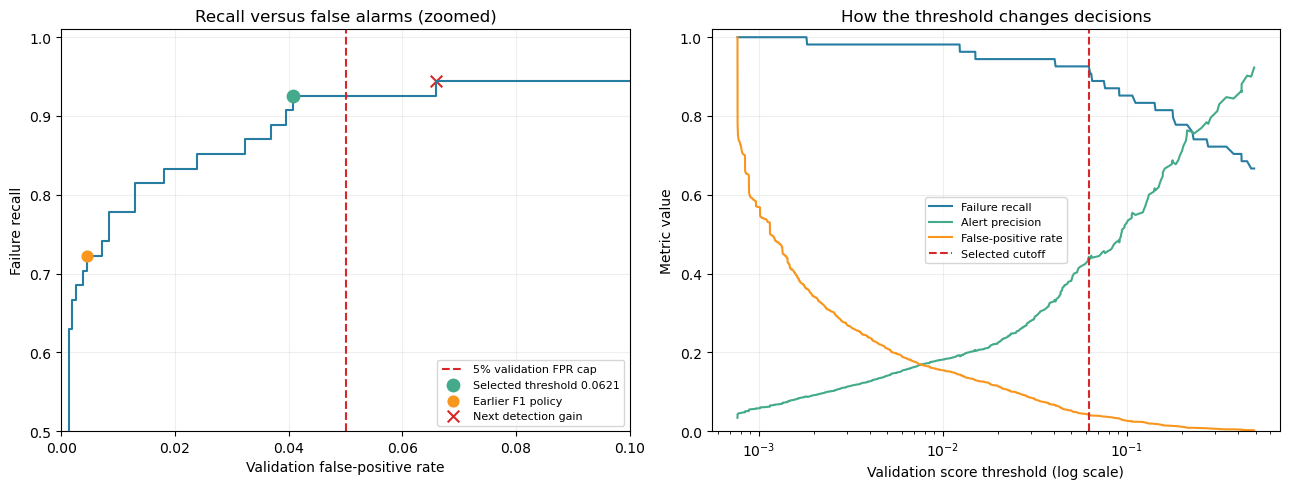

In [4]:
next_detection_options = threshold_grid.loc[
    threshold_grid["true_positives"].gt(selected_validation["true_positives"])
]
next_detection = None
if not next_detection_options.empty:
    next_detection = next_detection_options.sort_values(
        ["false_positives", "true_positives", "threshold"],
        ascending=[True, False, False],
    ).iloc[0]

decision_lines = [
    f"1. I evaluated **{len(threshold_grid)}** distinct alert patterns using validation scores only.",
    f"2. The validation set has **{validation_normal} normal observations**. "
    f"My **{MAX_VALIDATION_FPR:.0%} FPR cap** permits at most **{allowed_validation_false_alarms} false alarms**.",
    f"3. The largest feasible number of detected failures is **{int(selected_validation['true_positives'])}"
    f"/{validation_failures}**, giving **{selected_validation['recall']:.2%} recall**.",
    f"4. Among thresholds achieving that recall within the cap, I chose **{SELECTED_THRESHOLD:.15f}** "
    f"to minimize false alarms: **{int(selected_validation['false_positives'])}**, "
    f"or **{selected_validation['false_positive_rate']:.2%}** of normal observations.",
    f"5. This leaves **{int(selected_validation['false_negatives'])} missed failures** and produces "
    f"**{int(selected_validation['alerts'])} alerts**. Of these alerts, "
    f"**{selected_validation['false_discovery_rate']:.2%} are false alarms** "
    f"(precision **{selected_validation['precision']:.2%}**).",
    f"6. Compared with the earlier maximum-F1 threshold, this catches "
    f"**{int(selected_validation['true_positives'] - earlier_f1['true_positives'])} more failures** "
    f"and adds **{int(selected_validation['false_positives'] - earlier_f1['false_positives'])} false alarms**.",
]
if next_detection is not None:
    decision_lines.append(
        f"7. Detecting more failures requires at least **{int(next_detection['false_positives'])} false alarms** "
        f"in this validation ranking. The next such operating point is **{next_detection['threshold']:.15f}**, "
        f"detecting **{int(next_detection['true_positives'])} failures** at "
        f"**{next_detection['false_positive_rate']:.2%} FPR**. That adds "
        f"**{int(next_detection['true_positives'] - selected_validation['true_positives'])} detected failure(s)** "
        f"and **{int(next_detection['false_positives'] - selected_validation['false_positives'])} false alarms**, "
        "so it exceeds my chosen cap."
    )
decision_lines.append(
    "The selected FPR can be below 5% because predictions change in discrete steps and "
    "I prefer fewer false alarms when recall is tied. The cap is a validation selection constraint, "
    "not a guarantee for future observations."
)
decision_markdown = "\n\n".join(decision_lines)
display(Markdown(decision_markdown))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.plot(threshold_grid["false_positive_rate"], threshold_grid["recall"], color="#277DA1", linewidth=1.5)
ax.axvline(MAX_VALIDATION_FPR, color="#D62828", linestyle="--", label="5% validation FPR cap")
ax.scatter(
    [selected_validation["false_positive_rate"]], [selected_validation["recall"]],
    color="#43AA8B", s=80, zorder=4, label=f"Selected threshold {SELECTED_THRESHOLD:.4f}",
)
ax.scatter([earlier_f1["false_positive_rate"]], [earlier_f1["recall"]], color="#F8961E", s=60, zorder=4, label="Earlier F1 policy")
if next_detection is not None:
    ax.scatter([next_detection["false_positive_rate"]], [next_detection["recall"]], color="#D62828", marker="x", s=70, label="Next detection gain")
ax.set(xlim=(0, 0.10), ylim=(0.5, 1.01), xlabel="Validation false-positive rate", ylabel="Failure recall", title="Recall versus false alarms (zoomed)")
ax.grid(alpha=0.2)
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
ordered = threshold_grid.loc[
    threshold_grid["threshold"].gt(0) & threshold_grid["threshold"].le(0.5)
].sort_values("threshold")
for metric, label, color in [
    ("recall", "Failure recall", "#277DA1"),
    ("precision", "Alert precision", "#43AA8B"),
    ("false_positive_rate", "False-positive rate", "#F8961E"),
]:
    ax.plot(ordered["threshold"], ordered[metric], label=label, color=color)
ax.axvline(SELECTED_THRESHOLD, color="#D62828", linestyle="--", label="Selected cutoff")
ax.set(xscale="log", xlabel="Validation score threshold (log scale)", ylabel="Metric value", ylim=(0, 1.02), title="How the threshold changes decisions")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(VISUALS / "validation_threshold_decision.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Freeze the prediction and evaluation protocol

I now freeze the model artifact, feature preparation, score representation, exact threshold, selection rule, and evaluation methods. I save the protocol before the first final-test prediction.

I retain the fitted model trained on the original training partition. Refitting it on training plus validation would create a different scoring model and could change the meaning of the selected threshold.

If I rerun this notebook, an existing protocol must match. After seeing test performance, I do not change the threshold or select another model using this test set.

In [5]:
protocol = {
    "protocol_version": 1,
    "candidate": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "feature_set": schema["feature_set"],
    "raw_input_columns": RAW_COLUMNS,
    "model_input_columns": MODEL_COLUMNS,
    "decision": "predict failure when selected model score >= threshold",
    "threshold": SELECTED_THRESHOLD,
    "threshold_selection_split": "validation",
    "objective": "maximize validation true positives subject to the validation false-positive-rate cap",
    "validation_FPR_cap": MAX_VALIDATION_FPR,
    "cap_basis": "agreed project operating preference; business costs are not quantified",
    "tie_breaking": ["fewest false positives", "highest threshold"],
    "validation_normal_rows": validation_normal,
    "maximum_validation_false_positives": allowed_validation_false_alarms,
    "model_refitted": False,
    "model_training_rows": len(train_ids),
    "validation_rows": len(validation_ids),
    "reserved_final_test_rows": len(test_ids),
    "metrics": [
        "recall", "false_positive_rate", "precision", "false_discovery_rate",
        "f1", "accuracy", "balanced_accuracy", "average_precision",
        "roc_auc", "Brier_score", "log_loss", "alert_rate",
    ],
    "interval_methods": {
        "proportions": "Wilson intervals for the fixed test policy",
        "AP_ROC_F1_Brier_logloss": "percentile stratified row bootstrap; fixed class counts and predictor",
        "confidence_level": CONFIDENCE_LEVEL,
        "bootstrap_repeats": BOOTSTRAP_REPEATS,
    },
    "seed": SEED,
    "early_EDA_included_final_test_rows": metadata["early_EDA_included_final_test_rows"],
    "input_checksums": input_checksums,
}
protocol_path = REPORTS / "frozen_protocol.json"
test_predictions_path = REPORTS / "final_test_predictions.csv"
if protocol_path.exists():
    previous_protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    if previous_protocol != protocol:
        raise RuntimeError(
            "An existing final evaluation uses a different frozen protocol. "
            "Do not use the already exposed test set to tune a new policy."
        )
elif test_predictions_path.exists():
    raise RuntimeError("Test predictions exist without a frozen protocol; inspect the experiment history.")
else:
    protocol_path.write_text(json.dumps(protocol, indent=2), encoding="utf-8")
protocol_sha256 = sha256(protocol_path)
assert json.loads(protocol_path.read_text(encoding="utf-8")) == protocol
print("Frozen protocol saved before final-test scoring.")
print(f"Threshold: {SELECTED_THRESHOLD:.15f}; validation FPR cap: {MAX_VALIDATION_FPR:.0%}")
print("Model artifact SHA-256:", input_checksums["model"])

Frozen protocol saved before final-test scoring.
Threshold: 0.062125949322206; validation FPR cap: 5%
Model artifact SHA-256: 3b0ee78c9863d9b277c1d9e5afd40aa6cf4f0922904d67ceed813ae64c345985


## 7. Evaluate the reserved final test set

I apply the frozen policy to the reserved test observations without retraining, recalibrating, or searching test thresholds. I report the observed test FPR against the 5% selection cap and retain the result even if the cap is exceeded.

These observations have not previously been scored in the modeling workflow, but the early exploratory notebooks included the full dataset. This evaluation therefore has an earlier EDA exposure limitation. The random split also does not establish performance on future time periods or new machines.

In [6]:
assert protocol_path.is_file() and sha256(protocol_path) == protocol_sha256
X_test_raw = data_by_id.loc[test_ids, RAW_COLUMNS].copy()
y_test = data_by_id.loc[test_ids, TARGET].astype(int).copy()
if set(y_test.unique()) != {0, 1}:
    raise ValueError("Both classes must be present for this final evaluation.")
test_scores = predict_raw(X_test_raw)
test_decisions = (test_scores >= SELECTED_THRESHOLD).astype(int)
test_results = {
    **decision_metrics(y_test, test_scores, SELECTED_THRESHOLD),
    **score_metrics(y_test, test_scores),
}
validation_results = {
    **decision_metrics(y_validation, validation_scores, SELECTED_THRESHOLD),
    **score_metrics(y_validation, validation_scores),
}
performance = pd.DataFrame([
    dict(split="validation_policy_selection", **validation_results),
    dict(split="final_test", **test_results),
]).set_index("split")
test_predictions = X_test_raw.copy()
test_predictions[TARGET] = y_test
test_predictions["failure_score"] = test_scores
test_predictions["predicted_failure"] = test_decisions
test_predictions["threshold"] = SELECTED_THRESHOLD
test_predictions["outcome"] = np.select(
    [
        y_test.eq(1) & (test_decisions == 1),
        y_test.eq(0) & (test_decisions == 1),
        y_test.eq(1) & (test_decisions == 0),
    ],
    ["TP", "FP", "FN"], default="TN",
)
test_predictions.index.name = "UDI"
if test_predictions_path.exists():
    previous = pd.read_csv(test_predictions_path).set_index("UDI", verify_integrity=True)
    if set(previous.index) != set(test_ids):
        raise ValueError("Existing test prediction IDs differ.")
    np.testing.assert_allclose(
        previous.loc[test_ids, "failure_score"], test_scores, atol=1e-10, rtol=0
    )
    np.testing.assert_array_equal(previous.loc[test_ids, "predicted_failure"], test_decisions)
test_predictions.to_csv(test_predictions_path)
test_summary_path = REPORTS / "final_test_summary.json"
initial_test_summary = {
    "protocol_sha256": protocol_sha256,
    "source_model_sha256": input_checksums["model"],
    "final_test_scored": True,
    "threshold": SELECTED_THRESHOLD,
    "observed_test_FPR_at_or_below_cap": bool(test_results["false_positive_rate"] <= MAX_VALIDATION_FPR),
    "metrics": test_results,
}
test_summary_path.write_text(json.dumps(initial_test_summary, indent=2), encoding="utf-8")
display(performance[[
    "rows", "failures", "true_positives", "false_negatives", "false_positives",
    "recall", "false_positive_rate", "precision", "f1", "average_precision",
]])
print(classification_report(y_test, test_decisions, target_names=["No failure", "Failure"], labels=[0, 1], zero_division=0))
print("Observed test FPR at or below 5%:", initial_test_summary["observed_test_FPR_at_or_below_cap"])

              precision    recall  f1-score   support

  No failure       1.00      0.95      0.97      1932
     Failure       0.41      0.90      0.56        68

    accuracy                           0.95      2000
   macro avg       0.70      0.93      0.77      2000
weighted avg       0.98      0.95      0.96      2000

Observed test FPR at or below 5%: True


,rows,failures,true_positives,false_negatives,false_positives,recall,false_positive_rate,precision,f1,average_precision
split,,,,,,,,,,
validation_policy_selection,1600,54,50,4,63,0.925926,0.040750,0.442478,0.598802,0.841875
final_test,2000,68,61,7,88,0.897059,0.045549,0.409396,0.562212,0.870254


## 8. Quantify uncertainty

I report 95% Wilson intervals for test recall, FPR, precision, false-discovery rate, specificity, accuracy, and alert rate. Their denominators differ: recall uses actual failures, FPR uses normal observations, and precision uses alerts.

For AP, ROC AUC, F1, Brier score, and log loss, I use 2,000 stratified row-bootstrap samples with the model and threshold held fixed. These intervals condition on the observed class counts and do not include model-training uncertainty or changes in failure prevalence.

All intervals assume independent observations. Correlated sensor observations and the earlier EDA exposure limit how strongly I can generalize them. An observed FPR below 5% does not guarantee the true or future FPR is below 5%. [Wilson interval reference](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.stats._result_classes.BinomTestResult.proportion_ci.html)

In [7]:
tp, fp = test_results["true_positives"], test_results["false_positives"]
fn, tn = test_results["false_negatives"], test_results["true_negatives"]
proportion_definitions = {
    "recall": (tp, tp + fn),
    "false_positive_rate": (fp, fp + tn),
    "precision": (tp, tp + fp),
    "false_discovery_rate": (fp, tp + fp),
    "specificity": (tn, tn + fp),
    "accuracy": (tp + tn, tp + fp + fn + tn),
    "alert_rate": (tp + fp, tp + fp + fn + tn),
}
interval_records = []
for metric, (successes, trials) in proportion_definitions.items():
    if trials:
        interval = binomtest(successes, trials).proportion_ci(
            confidence_level=CONFIDENCE_LEVEL, method="wilson"
        )
        low, high = float(interval.low), float(interval.high)
    else:
        low, high = np.nan, np.nan
    interval_records.append({
        "metric": metric, "estimate": test_results[metric],
        "CI_low": low, "CI_high": high, "method": "Wilson",
        "successes": successes, "denominator": trials,
    })

bootstrap_rng = np.random.default_rng(SEED)
y_test_array = y_test.to_numpy()
positive_indices = np.flatnonzero(y_test_array == 1)
negative_indices = np.flatnonzero(y_test_array == 0)
bootstrap_records = []
for repeat in range(BOOTSTRAP_REPEATS):
    sampled = np.r_[
        bootstrap_rng.choice(positive_indices, len(positive_indices), replace=True),
        bootstrap_rng.choice(negative_indices, len(negative_indices), replace=True),
    ]
    sampled_y = y_test_array[sampled]
    sampled_scores = test_scores[sampled]
    sampled_decision = decision_metrics(sampled_y, sampled_scores, SELECTED_THRESHOLD)
    bootstrap_records.append({
        "repeat": repeat + 1, "f1": sampled_decision["f1"],
        **score_metrics(sampled_y, sampled_scores),
    })
bootstrap_results = pd.DataFrame(bootstrap_records)
alpha = 1 - CONFIDENCE_LEVEL
for metric in ["average_precision", "roc_auc", "f1", "Brier_score", "log_loss"]:
    low, high = bootstrap_results[metric].quantile([alpha / 2, 1 - alpha / 2])
    interval_records.append({
        "metric": metric, "estimate": test_results[metric],
        "CI_low": float(low), "CI_high": float(high),
        "method": "stratified percentile bootstrap",
        "successes": np.nan, "denominator": len(y_test),
    })
test_intervals = pd.DataFrame(interval_records)
display(test_intervals)
fpr_interval = test_intervals.loc[test_intervals["metric"].eq("false_positive_rate")].iloc[0]
print(f"Test FPR: {test_results['false_positive_rate']:.2%}; 95% Wilson interval "
      f"{fpr_interval['CI_low']:.2%} to {fpr_interval['CI_high']:.2%}.")

Test FPR: 4.55%; 95% Wilson interval 3.71% to 5.58%.


,metric,estimate,CI_low,CI_high,method,successes,denominator
0,recall,0.897059,0.802421,0.949234,Wilson,61.0,68
1,false_positive_rate,0.045549,0.037119,0.055782,Wilson,88.0,1932
2,precision,0.409396,0.333684,0.489662,Wilson,61.0,149
3,false_discovery_rate,0.590604,0.510338,0.666316,Wilson,88.0,149
4,specificity,0.954451,0.944218,0.962881,Wilson,1844.0,1932
5,accuracy,0.952500,0.942279,0.960986,Wilson,1905.0,2000
6,alert_rate,0.074500,0.063790,0.086842,Wilson,149.0,2000
7,average_precision,0.870254,0.798832,0.932843,stratified percentile bootstrap,NaN,2000
8,roc_auc,0.972963,0.943352,0.993478,stratified percentile bootstrap,NaN,2000
9,f1,0.562212,0.502323,0.620690,stratified percentile bootstrap,NaN,2000


## 9. Visualize final performance

The confusion matrix shows detected failures, missed failures, and false alarms at the frozen threshold. The precision–recall and ROC plots describe the selected model's test scores; I mark the frozen operating point and do not use these curves to choose another cutoff.

Average precision summarizes the precision–recall ranking and does not change when I change only the decision threshold. It is calculated directly from scores rather than as trapezoidal PR area. [AP reference](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.average_precision_score.html)

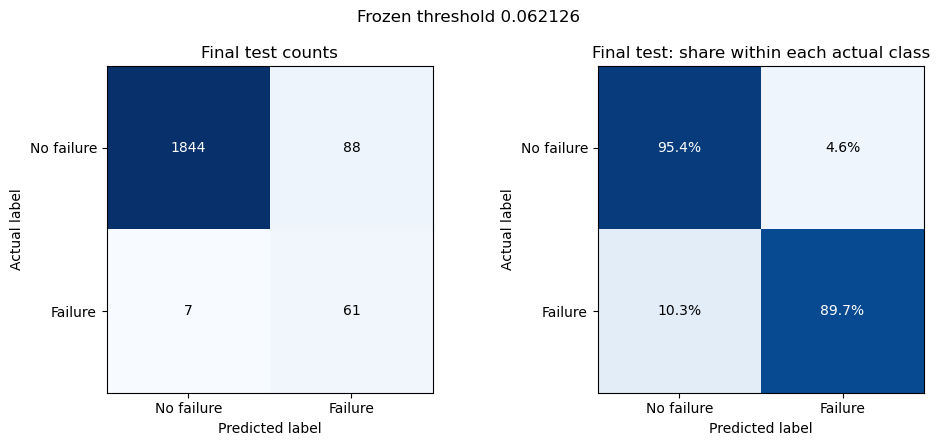

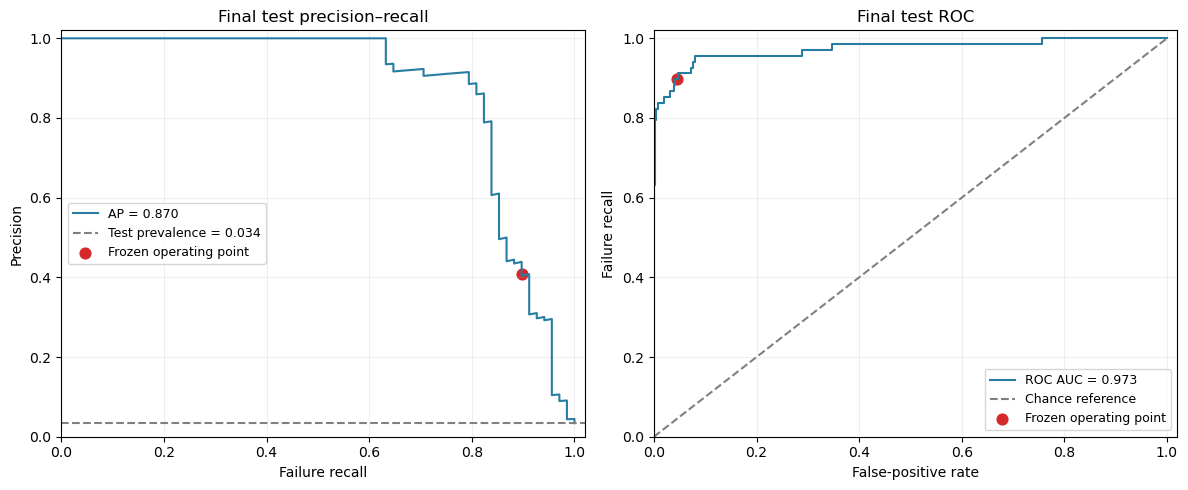

In [8]:
test_cm = confusion_matrix(y_test, test_decisions, labels=[0, 1])
row_normalized = test_cm / test_cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, matrix, title, is_percent in [
    (axes[0], test_cm, "Final test counts", False),
    (axes[1], row_normalized, "Final test: share within each actual class", True),
]:
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1 if is_percent else int(test_cm.max()))
    for row in range(2):
        for column in range(2):
            value = matrix[row, column]
            label = f"{value:.1%}" if is_percent else str(int(value))
            ax.text(column, row, label, ha="center", va="center",
                    color="white" if value > (0.5 if is_percent else test_cm.max() / 2) else "black")
    ax.set_xticks([0, 1], ["No failure", "Failure"])
    ax.set_yticks([0, 1], ["No failure", "Failure"])
    ax.set(xlabel="Predicted label", ylabel="Actual label", title=title)
fig.suptitle(f"Frozen threshold {SELECTED_THRESHOLD:.6f}")
fig.tight_layout()
fig.savefig(VISUALS / "final_test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_scores)
test_fpr_curve, test_tpr_curve, _ = roc_curve(y_test, test_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(pr_recall, pr_precision, color="#277DA1", label=f"AP = {test_results['average_precision']:.3f}")
axes[0].axhline(float(y_test.mean()), color="gray", linestyle="--", label=f"Test prevalence = {y_test.mean():.3f}")
axes[0].scatter([test_results["recall"]], [test_results["precision"]], color="#D62828", s=60, label="Frozen operating point")
axes[0].set(xlabel="Failure recall", ylabel="Precision", title="Final test precision–recall", xlim=(0, 1.02), ylim=(0, 1.02))
axes[1].plot(test_fpr_curve, test_tpr_curve, color="#277DA1", label=f"ROC AUC = {test_results['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance reference")
axes[1].scatter([test_results["false_positive_rate"]], [test_results["recall"]], color="#D62828", s=60, label="Frozen operating point")
axes[1].set(xlabel="False-positive rate", ylabel="Failure recall", title="Final test ROC", xlim=(0, 1.02), ylim=(0, 1.02))
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(VISUALS / "final_test_ranking_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Review errors and product-type results

I save all false alarms and missed failures for review. I also describe performance separately for each product type, always using the same frozen threshold.

These subgroup results are descriptive. Small failure counts make subgroup recall unstable, and I do not tune separate type-specific cutoffs from these test results.

In [9]:
test_errors = test_predictions.loc[test_predictions["outcome"].isin(["FP", "FN"])].copy()
subgroup_records = []
for product_type, subset in test_predictions.groupby("Type", observed=True):
    record = {
        "Type": product_type,
        **decision_metrics(subset[TARGET], subset["failure_score"], SELECTED_THRESHOLD),
    }
    if record["failures"]:
        interval = binomtest(record["true_positives"], record["failures"]).proportion_ci(
            confidence_level=CONFIDENCE_LEVEL, method="wilson"
        )
        record["recall_CI_low"], record["recall_CI_high"] = float(interval.low), float(interval.high)
    else:
        record["recall_CI_low"], record["recall_CI_high"] = np.nan, np.nan
    subgroup_records.append(record)
subgroup_results = pd.DataFrame(subgroup_records)
display(subgroup_results[[
    "Type", "rows", "failures", "true_positives", "false_negatives",
    "false_positives", "recall", "recall_CI_low", "recall_CI_high", "precision", "false_positive_rate",
]])
display(test_errors.sort_values(["outcome", "failure_score"], ascending=[True, False]).head(20))
print(f"All {len(test_errors)} test errors are saved in the final evaluation reports.")

All 95 test errors are saved in the final evaluation reports.


,Type,rows,failures,true_positives,false_negatives,false_positives,recall,recall_CI_low,recall_CI_high,precision,false_positive_rate
0,H,214,5,5,0,8,1.000000,0.565518,1.000000,0.384615,0.038278
1,L,1170,38,34,4,52,0.894737,0.758695,0.958297,0.395349,0.045936
2,M,616,25,22,3,28,0.880000,0.700442,0.958332,0.440000,0.047377


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,Machine failure,failure_score,predicted_failure,threshold,outcome
UDI,,,,,,,,,,,
3696,302.2,311.3,1530,37.3,207,L,1,0.061352,0,0.062126,FN
2942,300.7,309.6,1996,19.8,203,M,1,0.037587,0,0.062126,FN
7088,300.6,310.3,1648,30.5,217,L,1,0.033896,0,0.062126,FN
2672,299.7,309.3,1399,41.9,221,M,1,0.031634,0,0.062126,FN
9175,297.8,308.9,1871,25.6,200,L,1,0.002566,0,0.062126,FN
1997,298.4,308.0,1416,38.2,198,M,1,0.001968,0,0.062126,FN
8507,298.4,309.6,1710,27.3,163,L,1,0.000768,0,0.062126,FN
3795,302.2,310.8,1356,48.3,36,M,0,0.668782,1,0.062126,FP
4232,302.2,310.8,1340,47.8,54,L,0,0.662394,1,0.062126,FP


## 11. Summarize the decision and final result

I distinguish the validation evidence used to select the threshold from the test evidence used to evaluate the frozen policy. The 5% constraint applies to the empirical validation selection, so I separately report whether the test estimate meets it.

AI4I 2020 is a synthetic dataset. This project is a benchmark and does not establish that this alert policy is ready for deployment. I still need real operating costs, inspection capacity, and independent data from the intended machines and time periods. [Dataset reference](https://archive.ics.uci.edu/dataset/601/ai4i%2B2020%2Bpredictive%2Bmaintenance%2Bdataset)

In [10]:
observed_test_cap_met = bool(test_results["false_positive_rate"] <= MAX_VALIDATION_FPR)
cap_statement = (
    "The observed test FPR is at or below the 5% cap."
    if observed_test_cap_met else
    "The observed test FPR exceeds the 5% cap; I retain this result and do not retune on the test set."
)
summary_lines = [
    "# Final evaluation summary",
    f"I selected **{metadata['candidate']}** in the modeling stage and retained its "
    f"**{metadata['score_representation']}** score representation.",
    "## Why I used this threshold",
    f"I prioritized failure recall subject to an agreed **{MAX_VALIDATION_FPR:.0%} validation FPR cap**. "
    f"The complete validation search selected **{SELECTED_THRESHOLD:.15f}**, detecting "
    f"**{int(selected_validation['true_positives'])}/{validation_failures} failures** "
    f"with **{int(selected_validation['false_positives'])} false alarms**. "
    "I saved the model hash, feature rules, threshold, and evaluation protocol before final-test scoring.",
    "## Final test results",
    f"- Observations: **{len(y_test)}**, including **{test_results['failures']} failures**.",
    f"- Detected failures: **{tp}**; missed failures: **{fn}**.",
    f"- Recall: **{test_results['recall']:.2%}**.",
    f"- False alarms: **{fp}**; FPR among normal observations: **{test_results['false_positive_rate']:.2%}**.",
    f"- Precision: **{test_results['precision']:.2%}**; false alarms among alerts: **{test_results['false_discovery_rate']:.2%}**.",
    f"- F1: **{test_results['f1']:.4f}**; AP: **{test_results['average_precision']:.4f}**; ROC AUC: **{test_results['roc_auc']:.4f}**.",
    f"- {cap_statement}",
    f"- The test FPR 95% Wilson interval is **{fpr_interval['CI_low']:.2%}–{fpr_interval['CI_high']:.2%}**.",
    "## Limits and next steps",
    "- The test was previously included in early EDA, so this is not a fully blinded external evaluation.",
    "- The split is random and does not establish generalization to later time periods or different machines.",
    "- The dataset is synthetic; interval calculations assume independent rows.",
    "- The 5% FPR cap does not limit the false-alarm share of alerts to 5%. Alert workload still needs operational review.",
    "- I did not refit, recalibrate, change the threshold, or select another model after test scoring.",
    "- I next need an inference interface using the saved feature preparation and policy, followed by independent operational validation.",
]
final_summary_markdown = "\n\n".join(summary_lines)
display(Markdown(final_summary_markdown))

# Final evaluation summary

I selected **weighted_voting** in the modeling stage and retained its **uncalibrated** score representation.

## Why I used this threshold

I prioritized failure recall subject to an agreed **5% validation FPR cap**. The complete validation search selected **0.062125949322206**, detecting **50/54 failures** with **63 false alarms**. I saved the model hash, feature rules, threshold, and evaluation protocol before final-test scoring.

## Final test results

- Observations: **2000**, including **68 failures**.

- Detected failures: **61**; missed failures: **7**.

- Recall: **89.71%**.

- False alarms: **88**; FPR among normal observations: **4.55%**.

- Precision: **40.94%**; false alarms among alerts: **59.06%**.

- F1: **0.5622**; AP: **0.8703**; ROC AUC: **0.9730**.

- The observed test FPR is at or below the 5% cap.

- The test FPR 95% Wilson interval is **3.71%–5.58%**.

## Limits and next steps

- The test was previously included in early EDA, so this is not a fully blinded external evaluation.

- The split is random and does not establish generalization to later time periods or different machines.

- The dataset is synthetic; interval calculations assume independent rows.

- The 5% FPR cap does not limit the false-alarm share of alerts to 5%. Alert workload still needs operational review.

- I did not refit, recalibrate, change the threshold, or select another model after test scoring.

- I next need an inference interface using the saved feature preparation and policy, followed by independent operational validation.

## 12. Save the frozen model, policy, and evaluation evidence

I save the exact fitted predictor alongside its input schema and decision policy. The pipeline still requires the engineered columns described by the schema; the raw-input preparation function above creates them.

I also save the full validation threshold grid and decision explanation, final test predictions, uncertainty calculations, errors, subgroup results, and summary. The original model and earlier experiment files stay unchanged.

In [11]:
threshold_grid.to_csv(REPORTS / "validation_threshold_grid.csv", index=False)
cap_comparison.to_csv(REPORTS / "validation_FPR_cap_comparison.csv", index=False)
validation_comparison.to_csv(REPORTS / "validation_policy_comparison.csv", index=False)
(REPORTS / "threshold_decision.md").write_text(decision_markdown + "\n", encoding="utf-8")
performance.to_csv(REPORTS / "validation_and_test_metrics.csv")
test_intervals.to_csv(REPORTS / "final_test_metric_intervals.csv", index=False)
bootstrap_results.to_csv(REPORTS / "final_test_bootstrap_metrics.csv", index=False)
test_errors.to_csv(REPORTS / "final_test_errors.csv")
subgroup_results.to_csv(REPORTS / "final_test_by_Type.csv", index=False)
(REPORTS / "final_summary.md").write_text(final_summary_markdown + "\n", encoding="utf-8")
pd.DataFrame(classification_report(
    y_test, test_decisions, labels=[0, 1], target_names=["No failure", "Failure"],
    output_dict=True, zero_division=0,
)).T.to_csv(REPORTS / "final_test_classification_report.csv")

exported_predictor_path = MODELS / "predictor.joblib"
exported_predictor_path.write_bytes(INPUTS["model"].read_bytes())
(MODELS / "input_schema.json").write_text(json.dumps(schema, indent=2), encoding="utf-8")
decision_policy = {
    "candidate": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "positive_class": 1,
    "threshold": SELECTED_THRESHOLD,
    "comparison": ">=",
    "objective": protocol["objective"],
    "validation_FPR_cap": MAX_VALIDATION_FPR,
    "threshold_selection_split": "validation",
    "protocol_sha256": protocol_sha256,
    "source_model_sha256": input_checksums["model"],
    "feature_preparation_required_before_pipeline": schema["feature_preparation_required_before_pipeline"],
    "production_validated": False,
}
(MODELS / "decision_policy.json").write_text(json.dumps(decision_policy, indent=2), encoding="utf-8")
final_metadata = {
    "candidate": metadata["candidate"],
    "score_representation": metadata["score_representation"],
    "feature_set": schema["feature_set"],
    "model_training_rows": len(train_ids),
    "model_refitted": False,
    "final_test_scored": True,
    "final_test_rows": len(y_test),
    "policy_frozen_before_test_scoring": True,
    "threshold_changed_after_test_scoring": False,
    "operating_policy_status": "fixed project benchmark; operational acceptance pending",
    "production_validated": False,
    "early_EDA_included_final_test_rows": metadata["early_EDA_included_final_test_rows"],
    "protocol_sha256": protocol_sha256,
    "source_model_sha256": input_checksums["model"],
    "threshold": SELECTED_THRESHOLD,
    "validation_FPR_cap": MAX_VALIDATION_FPR,
    "observed_test_FPR_at_or_below_cap": observed_test_cap_met,
    "final_test_metrics": test_results,
    "input_checksums": input_checksums,
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "scipy": scipy.__version__, "joblib": joblib.__version__,
    },
}
(MODELS / "model_metadata.json").write_text(json.dumps(final_metadata, indent=2), encoding="utf-8")
initial_test_summary["metric_intervals"] = (
    test_intervals.astype(object).where(pd.notna(test_intervals), None).to_dict("records")
)
test_summary_path.write_text(json.dumps(initial_test_summary, indent=2), encoding="utf-8")

assert sha256(exported_predictor_path) == input_checksums["model"]
reloaded_predictor = joblib.load(exported_predictor_path)
reloaded_policy = json.loads((MODELS / "decision_policy.json").read_text(encoding="utf-8"))
np.testing.assert_allclose(
    predict_raw(X_validation_raw, fitted_predictor=reloaded_predictor),
    validation_scores, atol=1e-12, rtol=0,
)
assert reloaded_policy["threshold"] == SELECTED_THRESHOLD
assert sha256(protocol_path) == protocol_sha256
for name, path in INPUTS.items():
    assert sha256(path) == input_checksums[name], f"An earlier input changed: {name}"
assert set(test_predictions.index) == set(test_ids)
assert set(test_predictions.index).isdisjoint(set(train_ids) | set(validation_ids))
print("Saved reports:", REPORTS.relative_to(PROJECT_ROOT))
print("Saved figures:", VISUALS.relative_to(PROJECT_ROOT))
print("Saved exact model and policy:", MODELS.relative_to(PROJECT_ROOT))
print("Verified: exported model reloads; original inputs unchanged; fixed protocol retained.")

Saved reports: reports\final_evaluation
Saved figures: visuals\final_evaluation
Saved exact model and policy: models\final_evaluation
Verified: exported model reloads; original inputs unchanged; fixed protocol retained.
